# 3. Entrenamiento y comparación de modelos

En este notebook se entrenan los modelos que clasifican las imágenes y se elige el que se va a usar.

**Qué es entrenar un modelo.** Un clasificador de imágenes es una red neuronal: una función con millones de números ajustables, sus *pesos*, que recibe una imagen y devuelve una probabilidad para cada clase. **Entrenar** es mostrarle imágenes con su clase verdadera y ajustar los pesos poco a poco para que sus respuestas se acerquen a la verdad. **Validar** es medir cómo responde con imágenes que no usó para ajustarse; es lo único que dice si aprendió de verdad.

**Por qué se parte de un modelo ya entrenado.** Entrenar una red desde cero exige cientos de miles de imágenes y aquí hay 600. Lo habitual es partir de una red entrenada con más de un millón de fotografías generales (la base *ImageNet*), que ya reconoce bordes, texturas y formas, y adaptarla a estas 10 clases. A esto se le llama *transferencia de aprendizaje*.

**Los tres modelos que se comparan**, todos con el mismo protocolo:

- **YOLOv8n-cls**: la versión más pequeña (*nano*) de YOLOv8, una familia de redes de visión muy usada, en su variante para clasificar imágenes.
- **YOLOv8s-cls**: la versión siguiente (*small*), con más pesos. Solo reemplaza a la anterior si mejora lo suficiente, según una regla fijada antes de entrenar (sección 3.4).
- **ResNet-18**: una red clásica de otra familia. Sirve como referencia para saber si YOLO aporta algo.

**Cómo se entrena.** Cada modelo se entrena 5 veces, una por cada pliegue de la validación cruzada del notebook 1: con cuatro pliegues se entrena y con el quinto se valida. Cada entrenamiento tiene dos etapas. En la primera etapa solo se ajusta la cabeza, la parte final de la red que convierte sus rasgos en las 10 clases, y el resto de la red (el cuerpo), queda congelado (no cambia). En ResNet-18 la cabeza es una sola capa lineal; en YOLOv8 es el módulo de clasificación completo (una convolución 1 × 1 con su normalización, un promedio global y la capa lineal final). La capa lineal es nueva; el resto de la cabeza parte de los pesos de ImageNet. En la segunda etapa se ajusta toda la red con una **tasa de aprendizaje** más baja; la tasa es el tamaño de cada ajuste, y reducirla permite afinar sin deshacer lo que la red ya sabía. El entrenamiento avanza por **épocas** (una época es una pasada por todas las imágenes de entrenamiento) y cada etapa se detiene sola cuando el F1-macro de validación, la métrica principal que se define en la sección 3.4, lleva 15 épocas sin mejorar. Es la **parada temprana**, y de cada etapa se conserva la mejor época.
<br><small>Nota. El holdout no se usa en este notebook. Se necesita una GPU (en Colab: *Entorno de ejecución → Cambiar tipo de entorno*); con ella el entrenamiento completo tarda del orden de una hora.</small>



## 3.1 Configuración y datos

En Colab, el proyecto vive en una carpeta de Google Drive que contiene `dataset/` (y, desde el notebook 1, `salidas/`). Su ubicación se indica en `CARPETA_DRIVE`; al ejecutar, Colab pide una vez autorización para acceder a Drive y se ubica en esa carpeta. Así los cuatro notebooks leen y escriben en la misma `salidas/`, aunque cada uno corra en su propia sesión.

Los parámetros del entrenamiento:

- `IMGSZ = 224`: el lado, en píxeles, al que se reduce cada imagen antes de entrar a la red. Es el tamaño con el que se entrenaron los modelos de partida; subirlo con solo 600 imágenes aumentaría el riesgo de que el modelo memorice.
- `LADO_CACHE = 448`: las imágenes originales, de 1184 píxeles, se reducen una sola vez a 448 y se guardan en memoria para no volver a leerlas en cada época. Es el doble de la entrada, así que no se pierde detalle.
- `BATCH = 16`: cuántas imágenes se procesan juntas antes de cada ajuste de los pesos.
- `PACIENCIA = 15`: épocas sin mejorar que se toleran antes de detener una etapa.
- `ETAPA_1` y `ETAPA_2`: el máximo de épocas y la tasa de aprendizaje de cada etapa.

Luego se lee la partición del notebook 1, se comprueba con su código que no fue modificada y se cargan en memoria solo las imágenes de validación cruzada.

In [ ]:
%pip install -q ultralytics==8.3.203

from pathlib import Path
import os, sys
import copy, hashlib, json, random, time, warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms as T
from torch.utils.data import DataLoader, Dataset
from torchvision import models
from PIL import Image
from IPython.display import display
from scipy.cluster.hierarchy import fcluster, linkage
from scipy.spatial.distance import squareform
from scipy.stats import binomtest
from sklearn.metrics import (average_precision_score, balanced_accuracy_score, confusion_matrix, f1_score,
                             precision_recall_curve, precision_recall_fscore_support, roc_auc_score)

CARPETA_DRIVE = "MyDrive/Geologia_SCD"   # carpeta del proyecto en Google Drive (con dataset/ y salidas/)
if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")
    os.chdir(f"/content/drive/{CARPETA_DRIVE}")

DATASET_DIR = Path("dataset")
OUT_DIR = Path("salidas")

SEMILLA = 42
IMGSZ = 224
LADO_CACHE = 448
BATCH = 16
PACIENCIA = 15
ETAPA_1 = {"epocas_max": 20, "lr": 1e-3}   # solo la cabeza (en YOLOv8, el módulo Classify completo); el cuerpo, congelado
ETAPA_2 = {"epocas_max": 80, "lr": 1e-4}   # toda la red
VARIANTES = ["yolov8n-cls", "yolov8s-cls", "resnet18"]

DISPOSITIVO = "cuda" if torch.cuda.is_available() else "cpu"
torch.backends.cudnn.deterministic, torch.backends.cudnn.benchmark = True, False
warnings.filterwarnings("ignore", message="y_pred contains classes not in y_true")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 200)

def hash_particion(d):
    # misma definición que en el notebook 1
    cols = ["id", "clase", "grupo_particion", "split", "fold_val"]
    texto = d[cols].sort_values("id").to_csv(sep=";", index=False, lineterminator="\n", na_rep="")
    return hashlib.sha256(texto.encode("utf-8")).hexdigest()

part = pd.read_csv(OUT_DIR / "particion.csv", sep=";", encoding="utf-8-sig", dtype={"fold_val": "Int64"})
assert hash_particion(part) == (OUT_DIR / "particion.hash").read_text().strip(), "particion.csv fue modificado; vuelve a ejecutar el notebook 1."

CLASES = sorted(part["clase"].unique())
IDX = {c: i for i, c in enumerate(CLASES)}
N_PLIEGUES = int(part["fold_val"].max())
cv = part[part["split"] == "cv"].reset_index(drop=True)
cv["ruta"] = [DATASET_DIR / c / f"{i}.png" for c, i in zip(cv["carpeta"], cv["id"])]

def cargar_reducida(ruta):
    with Image.open(ruta) as im:
        return im.convert("RGB").resize((LADO_CACHE, LADO_CACHE), Image.LANCZOS)

CACHE = {int(i): cargar_reducida(r) for i, r in zip(cv["id"], cv["ruta"])}
print(f"Partición verificada. {len(CACHE)} imágenes de validación cruzada en memoria; el holdout ({(part['split'] == 'holdout').sum()}) no se carga.")
print("Dispositivo:", torch.cuda.get_device_name(0) if DISPOSITIVO == "cuda" else "CPU (sin GPU el entrenamiento será muy lento)")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 22.4 MB/s eta 0:00:00
Mounted at /content/drive
Partición verificada. 499 imágenes de validación cruzada en memoria; el holdout (101) no se carga.
Dispositivo: Tesla T4


In [ ]:
# ---------- Preparación de las imágenes ----------
class Giro90:
    """Gira la imagen 0, 90, 180 o 270 grados al azar."""
    GIROS = [None, Image.Transpose.ROTATE_90, Image.Transpose.ROTATE_180, Image.Transpose.ROTATE_270]
    def __call__(self, im):
        giro = random.choice(self.GIROS)
        return im if giro is None else im.transpose(giro)

def pasos_geometricos():
    return [T.RandomResizedCrop(IMGSZ, scale=(0.7, 1.0), ratio=(1.0, 1.0)), Giro90(),
            T.RandomHorizontalFlip(0.5), T.RandomVerticalFlip(0.5)]

def normalizacion(variante):
    # YOLOv8 solo lleva los píxeles a [0, 1]; ResNet espera además la normalización de ImageNet
    if variante.startswith("yolo"):
        return T.Normalize((0.0, 0.0, 0.0), (1.0, 1.0, 1.0))
    return T.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225))

def transformacion(variante, entrenamiento):
    pasos = pasos_geometricos() if entrenamiento else [T.Resize(IMGSZ)]
    return T.Compose(pasos + [T.ToTensor(), normalizacion(variante)])

class Imagenes(Dataset):
    def __init__(self, filas, transform):
        self.ids = filas["id"].astype(int).tolist()
        self.etiquetas = [IDX[c] for c in filas["clase"]]
        self.transform = transform
    def __len__(self):
        return len(self.ids)
    def __getitem__(self, i):
        return self.transform(CACHE[self.ids[i]]), self.etiquetas[i]

def cargadores(variante, k):
    entrenamiento, validacion = cv[cv["fold_val"] != k], cv[cv["fold_val"] == k]
    g = torch.Generator().manual_seed(SEMILLA + k)
    dl_ent = DataLoader(Imagenes(entrenamiento, transformacion(variante, True)), batch_size=BATCH, shuffle=True, generator=g, drop_last=True)
    dl_val = DataLoader(Imagenes(validacion, transformacion(variante, False)), batch_size=BATCH)
    return dl_ent, dl_val, validacion

# ---------- Modelos ----------
def construir_modelo(variante):
    """Red preentrenada con la última capa cambiada a nuestras 10 clases. Devuelve (red, cuerpo, cabeza)."""
    if variante.startswith("yolo"):
        from ultralytics import YOLO
        from ultralytics.nn.tasks import ClassificationModel
        red = YOLO(f"{variante}.pt").model.float()
        ClassificationModel.reshape_outputs(red, len(CLASES))
        cuerpo, cabeza = nn.ModuleList(red.model[:-1]), red.model[-1]
    else:
        red = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
        red.fc = nn.Linear(red.fc.in_features, len(CLASES))
        cuerpo, cabeza = nn.ModuleList([m for n, m in red.named_children() if n != "fc"]), red.fc
    for p in red.parameters():
        p.requires_grad_(True)
    return red.to(DISPOSITIVO), cuerpo, cabeza

def logits_de(red, x):
    salida = red(x)
    return salida[1] if isinstance(salida, (tuple, list)) else salida   # YOLO en evaluación devuelve (probabilidades, logits)

@torch.no_grad()
def predecir(red, cargador):
    red.eval()
    ys, ps = [], []
    for x, y in cargador:
        ps.append(torch.softmax(logits_de(red, x.to(DISPOSITIVO)), dim=1).cpu().numpy())
        ys.append(y.numpy())
    return np.concatenate(ys), np.concatenate(ps)

# ---------- Entrenamiento ----------
def f1_de_validacion(y, prob):
    # F1-macro sobre las clases que tienen imágenes en este pliegue
    return float(f1_score(y, prob.argmax(1), labels=sorted(set(y.tolist())), average="macro", zero_division=0))

def entrenar_etapa(red, cuerpo, congelar_cuerpo, cfg, dl_ent, dl_val, historia, contexto):
    for p in cuerpo.parameters():
        p.requires_grad_(not congelar_cuerpo) # congela SOLO el cuerpo
    opt = torch.optim.AdamW([p for p in red.parameters() if p.requires_grad], lr=cfg["lr"])
    mejor_f1, mejor_epoca, mejor_estado, sin_mejora = -1.0, 0, None, 0
    for epoca in range(1, cfg["epocas_max"] + 1):
        red.train()
        if congelar_cuerpo:
            cuerpo.eval()   # la parte congelada tampoco actualiza sus estadísticas internas
        perdida, n = 0.0, 0
        for x, y in dl_ent:
            x, y = x.to(DISPOSITIVO), y.to(DISPOSITIVO)
            opt.zero_grad()
            perdida_lote = F.cross_entropy(logits_de(red, x), y)
            perdida_lote.backward()
            opt.step()
            perdida += perdida_lote.item() * len(y)
            n += len(y)
        f1 = f1_de_validacion(*predecir(red, dl_val))
        historia.append({**contexto, "epoca": epoca, "perdida_entrenamiento": perdida / n, "f1_validacion": f1})
        if f1 > mejor_f1:
            mejor_f1, mejor_epoca, mejor_estado, sin_mejora = f1, epoca, copy.deepcopy(red.state_dict()), 0
        else:
            sin_mejora += 1
            if sin_mejora >= PACIENCIA:
                break
    red.load_state_dict(mejor_estado)
    return mejor_epoca, mejor_f1, epoca

def entrenar_pliegue(variante, k):
    random.seed(SEMILLA + k); np.random.seed(SEMILLA + k); torch.manual_seed(SEMILLA + k); torch.cuda.manual_seed_all(SEMILLA + k)
    red, cuerpo, _ = construir_modelo(variante)
    dl_ent, dl_val, _ = cargadores(variante, k)
    historia = []
    ep1, f1_1, _ = entrenar_etapa(red, cuerpo, True, ETAPA_1, dl_ent, dl_val, historia, {"modelo": variante, "pliegue": k, "etapa": 1})
    ep2, f1_2, n2 = entrenar_etapa(red, cuerpo, False, ETAPA_2, dl_ent, dl_val, historia, {"modelo": variante, "pliegue": k, "etapa": 2})
    resumen = {"mejor_epoca_etapa_1": ep1, "mejor_epoca_etapa_2": ep2, "f1_etapa_1": f1_1, "f1_etapa_2": f1_2, "epocas_etapa_2": n2}
    return red, historia, resumen

# ---------- Regiones geográficas ----------
def haversine_km(lat1, lon1, lat2, lon2):
    a, b = np.radians(lat1)[:, None], np.radians(lat2)[None, :]
    dlat, dlon = b - a, np.radians(lon2)[None, :] - np.radians(lon1)[:, None]
    h = np.sin(dlat / 2) ** 2 + np.cos(a) * np.cos(b) * np.sin(dlon / 2) ** 2
    return 2 * 6371.0 * np.arcsin(np.sqrt(np.clip(h, 0, 1)))

def regiones(lat, lon, km=1000):
    """Agrupa en una región los puntos unidos por saltos de menos de `km` y la nombra por su centro aproximado."""
    lat, lon = np.asarray(lat, float), np.asarray(lon, float)
    etiqueta = fcluster(linkage(squareform(haversine_km(lat, lon, lat, lon), checks=False), "single"), km, "distance")
    nombres = {}
    for e in sorted(set(etiqueta), key=lambda e: (-(etiqueta == e).sum(), lat[etiqueta == e].mean())):
        la, lo = lat[etiqueta == e].mean(), lon[etiqueta == e].mean()
        nombres[e] = f"{abs(la):.0f}°{'N' if la >= 0 else 'S'} {abs(lo):.0f}°{'E' if lo >= 0 else 'O'}"
    return np.array([nombres[e] for e in etiqueta])

## 3.2 Aumento de datos

Con pocas imágenes una red tiende a memorizarlas. El **aumento de datos** lo evita: en cada época cada imagen se muestra con una variación aleatoria distinta, de modo que la red nunca ve dos veces exactamente la misma. Aquí las variaciones son solo geométricas:

- **Giros** de 0, 90, 180 o 270 grados y **reflejos** horizontal y vertical: 8 orientaciones de la misma imagen. En una foto tomada desde arriba no hay «arriba» ni «abajo», y una depresión girada sigue siendo la misma depresión. No se usan otros ángulos porque dejarían esquinas vacías que habría que rellenar con un color inventado.
- Un **recorte cuadrado aleatorio** que conserva al menos el 70 % del área, para que la geoforma no salga del encuadre ni se deforme.

No se altera el color ni el brillo: en el notebook 4 se mide cuánto depende el modelo del color, y esa medida solo tiene sentido si nunca se entrenó con colores alterados. En validación no hay variaciones; la imagen solo se reduce a 224 píxeles.

La figura muestra, para cada clase, una imagen original y tres versiones aumentadas. Hay que comprobar a ojo que la geoforma sigue completa y reconocible.

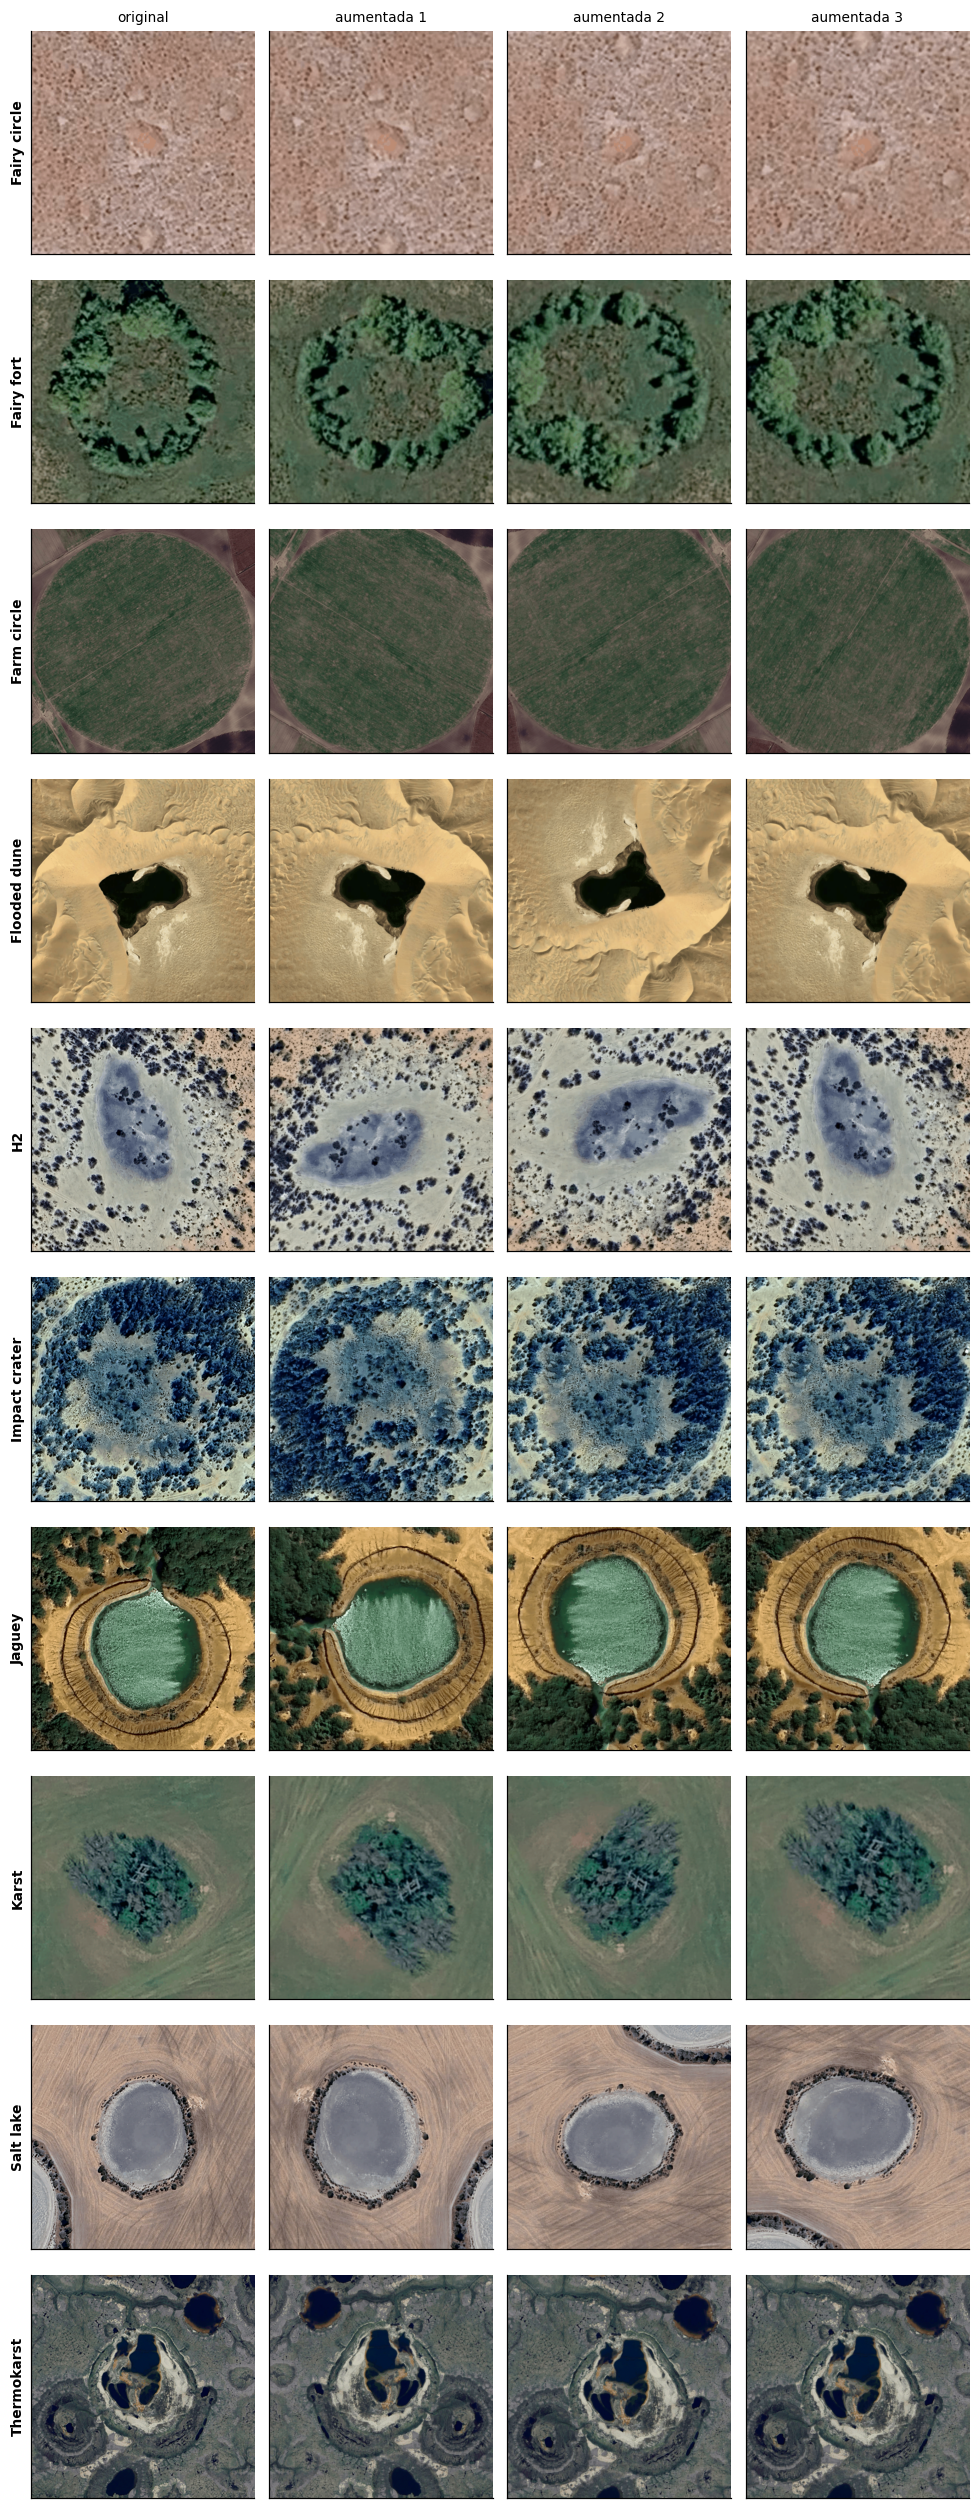

In [ ]:
rng = np.random.default_rng(SEMILLA)
random.seed(SEMILLA)
geometrico = T.Compose(pasos_geometricos())
fig, ejes = plt.subplots(len(CLASES), 4, figsize=(9, 2.3 * len(CLASES)))
for fila, clase in enumerate(CLASES):
    original = CACHE[int(rng.choice(cv.loc[cv["clase"] == clase, "id"]))]
    for col, im in enumerate([original.resize((IMGSZ, IMGSZ))] + [geometrico(original) for _ in range(3)]):
        ax = ejes[fila, col]
        ax.imshow(im); ax.set_xticks([]); ax.set_yticks([])
        if fila == 0:
            ax.set_title("original" if col == 0 else f"aumentada {col}", fontsize=9)
    ejes[fila, 0].set_ylabel(clase, fontsize=9, fontweight="bold")
fig.tight_layout()
plt.show()

## 3.3 Entrenamiento

Se entrenan los tres modelos en los cinco pliegues (5 vueltas) Al terminar cada vuelta se imprime la mejor época de cada etapa, cuántas épocas alcanzó a correr la etapa 2, el F1-macro de validación de la mejor época y los minutos que tardó. Cada modelo se guarda en `salidas/modelos/`; si el notebook se vuelve a ejecutar, los modelos que ya están guardados se cargan en lugar de entrenarse otra vez, lo que también permite retomar el trabajo si Colab se desconecta a mitad de camino.

Lo esperable son F1-macro altos y parecidos entre pliegues, y mejores épocas que no sean siempre la última, señal de que la parada temprana está actuando.

In [ ]:
(OUT_DIR / "modelos").mkdir(parents=True, exist_ok=True)
historias, resumenes, tiempos, tablas_pred = [], {}, [], []

for variante in VARIANTES:
    print(f"\n{variante}")
    for k in range(1, N_PLIEGUES + 1):
        ruta = OUT_DIR / "modelos" / f"{variante}_pliegue{k}.pt"
        if ruta.exists():
            guardado = torch.load(ruta, map_location="cpu", weights_only=True)
            red, _, _ = construir_modelo(variante)
            red.load_state_dict(guardado["state_dict"])
        else:
            inicio = time.time()
            red, historia_k, resumen_k = entrenar_pliegue(variante, k)
            guardado = {"state_dict": {n: v.cpu() for n, v in red.state_dict().items()}, "clases": CLASES,
                        "historia": historia_k, "resumen": resumen_k, "segundos": time.time() - inicio}
            torch.save(guardado, ruta)
        r = guardado["resumen"]
        print(f"  pliegue {k}: mejor época {r['mejor_epoca_etapa_1']} (etapa 1) y {r['mejor_epoca_etapa_2']} de {r['epocas_etapa_2']} (etapa 2)"
              f" · F1-macro {r['f1_etapa_2']:.3f} · {guardado['segundos'] / 60:.1f} min")
        historias += guardado["historia"]
        resumenes[(variante, k)] = r
        tiempos.append({"modelo": variante, "pliegue": k, "minutos": guardado["segundos"] / 60})

        _, dl_val, validacion = cargadores(variante, k)
        _, prob = predecir(red, dl_val)
        pred = validacion[["id", "clase", "grupo_particion", "zoom"]].reset_index(drop=True)
        pred["modelo"], pred["pliegue"], pred["pred"] = variante, k, [CLASES[i] for i in prob.argmax(1)]
        tablas_pred.append(pd.concat([pred, pd.DataFrame(prob, columns=[f"prob_{c}" for c in CLASES])], axis=1))
        del red
        if DISPOSITIVO == "cuda":
            torch.cuda.empty_cache()

historia = pd.DataFrame(historias)
predicciones = pd.concat(tablas_pred, ignore_index=True)
tiempos = pd.DataFrame(tiempos)


yolov8n-cls
Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
  pliegue 1: mejor época 16 (etapa 1) y 7 de 22 (etapa 2) · F1-macro 0.895 · 1.9 min
  pliegue 2: mejor época 20 (etapa 1) y 16 de 31 (etapa 2) · F1-macro 0.893 · 1.9 min
  pliegue 3: mejor época 9 (etapa 1) y 12 de 27 (etapa 2) · F1-macro 0.954 · 2.0 min
  pliegue 4: mejor época 16 (etapa 1) y 6 de 21 (etapa 2) · F1-macro 0.968 · 1.7 min
  pliegue 5: mejor época 5 (etapa 1) y 2 de 17 (etapa 2) · F1-macro 0.978 · 1.4 min

yolov8s-cls
  pliegue 1: mejor época 14 (etapa 1) y 9 de 24 (etapa 2) · F1-macro 0.918 · 1.7 min
  pliegue 2: mejor época 18 (etapa 1) y 44 de 59 (etapa 2) · F1-macro 0.912 · 3.5 min
  pliegue 3: mejor época 4 (etapa 1) y 8 de 23 (etapa 2) · F1-macro

100%|██████████| 44.7M/44.7M [00:00<00:00, 120MB/s]


  pliegue 1: mejor época 9 (etapa 1) y 29 de 44 (etapa 2) · F1-macro 0.922 · 2.9 min
  pliegue 2: mejor época 20 (etapa 1) y 10 de 25 (etapa 2) · F1-macro 0.907 · 2.0 min
  pliegue 3: mejor época 7 (etapa 1) y 9 de 24 (etapa 2) · F1-macro 0.934 · 1.9 min
  pliegue 4: mejor época 8 (etapa 1) y 17 de 32 (etapa 2) · F1-macro 0.967 · 2.4 min
  pliegue 5: mejor época 13 (etapa 1) y 8 de 23 (etapa 2) · F1-macro 0.989 · 1.9 min


El F1-macro de estas líneas es el de la mejor época de la etapa 2 en el pliegue de validación, el mismo que usó la parada temprana, y se calcula con las clases presentes en ese pliegue (incluida Fairy Circle cuando aparece, diez clases en este caso). La siguiente sección 3.4 calcula el F1-macro de las mismas predicciones solo con las nueve clases comparables presentes en los cinco pliegues de validación, exceptuándo Fairy Circle que solo está presente en los pliegues 3 y 5, por esta razón, los resultados de estos difieren en algunas milésismas de los calculados en el entrenamiento (presente sección).

Estas cifras son algo optimistas porque el pliegue de validación cumple dos funciones: elige la época que se conserva y mide su desempeño. Como el F1 de cada época tiene ruido (con unas 100 imágenes, una sola cambia la cifra cerca de 0,01), la mejor de entre 20 y 60 épocas tiende a ser una en la que el ruido jugó a favor. La estimación sin ese sesgo es la del holdout del notebook 4, que no interviene en ninguna elección.

La tabla siguiente da los minutos por pliegue y la figura, la evolución del F1-macro de validación durante la etapa 2, una línea por pliegue. Lo normal es una subida rápida y luego una meseta con altibajos: cada pliegue se valida con unas 100 imágenes, así que unos pocos aciertos bastan para mover la curva.

pliegue,1,2,3,4,5,total
modelo,,,,,,
resnet18,2.9,2.0,1.9,2.4,1.9,11.0
yolov8n-cls,1.9,1.9,2.0,1.7,1.4,9.0
yolov8s-cls,1.7,3.5,1.7,1.9,1.6,10.3


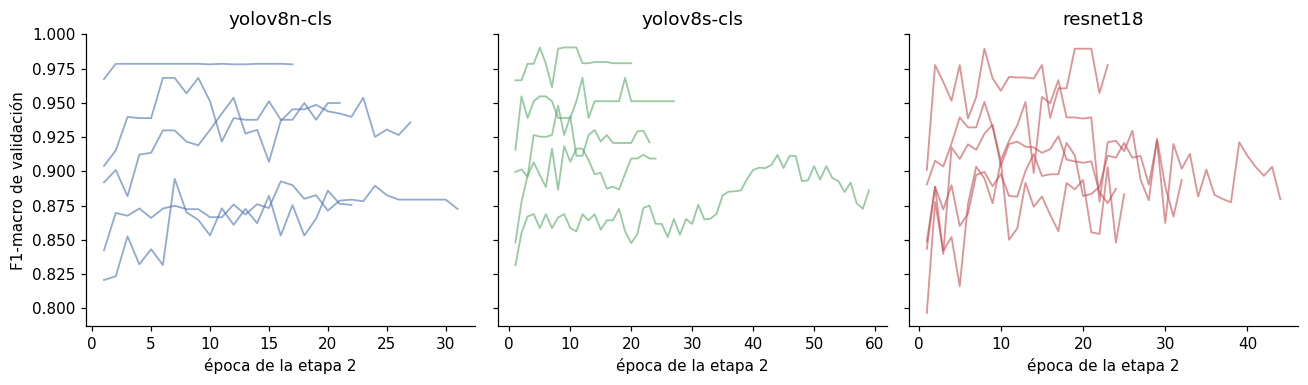

In [ ]:
tabla_tiempo = tiempos.pivot(index="modelo", columns="pliegue", values="minutos")
tabla_tiempo["total"] = tabla_tiempo.sum(axis=1)
display(tabla_tiempo.round(1))

colores = {"yolov8n-cls": "#4C72B0", "yolov8s-cls": "#55A868", "resnet18": "#C44E52"}
fig, ejes = plt.subplots(1, len(VARIANTES), figsize=(12, 3.6), sharey=True)
for ax, variante in zip(ejes, VARIANTES):
    for k, h in historia[(historia["modelo"] == variante) & (historia["etapa"] == 2)].groupby("pliegue"):
        ax.plot(h["epoca"], h["f1_validacion"], color=colores[variante], alpha=0.6, lw=1.2)
    ax.set_title(variante); ax.set_xlabel("época de la etapa 2")
ejes[0].set_ylabel("F1-macro de validación")
fig.tight_layout()
plt.show()

## 3.4 Comparación de los modelos

**Cómo se mide un clasificador.** Para cada clase, el modelo puede equivocarse de dos maneras, y por eso hay varias métricas:

- **Precisión** de una clase: de las imágenes que el modelo asignó a esa clase, cuántas lo eran. Si es baja, el modelo le atribuye cosas que no le pertenecen.
- **Recall** de una clase: de las imágenes que realmente son de esa clase, cuántas encontró. Si es bajo, se le escapan muchas.
- **F1**: combina precisión y recall en un solo número (su media armónica); solo es alto si los dos lo son.
- **F1-macro**: el promedio del F1 de todas las clases, con el mismo peso para cada una. Es la métrica principal del trabajo, porque un buen resultado en unas clases no puede esconder uno malo en otra.
- **Exactitud balanceada**: el promedio del recall de las clases.
- **F1 ponderado**: como el F1-macro, pero cada clase pesa según su número de imágenes.
- **AUC-ROC** (uno contra todos): mide, para cada clase, qué tan bien las probabilidades separan sus imágenes de las demás sin depender de un umbral; 1 es separación perfecta y 0,5 es azar. Se promedia entre clases.
- **PR-AUC de H2**: resume el equilibrio entre precisión y recall de H2 en todos los umbrales posibles (se ve en detalle en la sección 3.5). Es la medida que importa para usar la probabilidad de H2 como orden de prioridad.

Todas van de 0 a 1 y más alto es mejor; al azar, con 10 clases, el F1 y la exactitud balanceada rondan 0,1. Se calculan en cada pliegue y se reportan como media y desviación entre los cinco. Solo entran al promedio las clases que tienen imágenes de validación en los cinco pliegues; las demás se evalúan aparte en la sección 3.6.

In [ ]:
def metricas(d, clases):
    y, p = d["clase"], d["pred"]
    auc = [roc_auc_score(y == c, d[f"prob_{c}"]) for c in clases if 0 < (y == c).sum() < len(y)]
    return {"F1-macro": f1_score(y, p, labels=clases, average="macro", zero_division=0),
            "Exactitud balanceada": balanced_accuracy_score(y, p),
            "F1 ponderado": f1_score(y, p, labels=clases, average="weighted", zero_division=0),
            "AUC-ROC": float(np.mean(auc)),
            "PR-AUC de H2": average_precision_score(y == "H2", d["prob_H2"])}

clases_por_pliegue = cv.groupby("fold_val")["clase"].agg(set)
COMPARABLES = [c for c in CLASES if all(c in clases_por_pliegue[k] for k in range(1, N_PLIEGUES + 1))]
APARTE = [c for c in CLASES if c not in COMPARABLES]
print("Clases en el promedio:", ", ".join(COMPARABLES))
print("Clases evaluadas aparte:", ", ".join(APARTE) or "ninguna")

por_pliegue = pd.DataFrame([{"modelo": v, "pliegue": k, **metricas(g, COMPARABLES)} for (v, k), g in predicciones.groupby(["modelo", "pliegue"])])
media, desv = por_pliegue.groupby("modelo").mean().drop(columns="pliegue"), por_pliegue.groupby("modelo").std().drop(columns="pliegue")
display((media.map(lambda x: f"{x:.3f}") + " ± " + desv.map(lambda x: f"{x:.3f}")).reindex(VARIANTES))

Clases en el promedio: Fairy fort, Farm circle, Flooded dune, H2, Impact crater, Jaguey, Karst, Salt lake, Thermokarst
Clases evaluadas aparte: Fairy circle


,F1-macro,Exactitud balanceada,F1 ponderado,AUC-ROC,PR-AUC de H2
modelo,,,,,
yolov8n-cls,0.936 ± 0.040,0.942 ± 0.038,0.933 ± 0.044,0.992 ± 0.004,0.930 ± 0.074
yolov8s-cls,0.946 ± 0.033,0.951 ± 0.031,0.945 ± 0.033,0.994 ± 0.004,0.965 ± 0.033
resnet18,0.942 ± 0.034,0.950 ± 0.028,0.940 ± 0.038,0.995 ± 0.004,0.957 ± 0.043


Los tres modelos quedan muy cerca. El F1-macro medio va de 0,936 (YOLOv8n) a 0,946 (YOLOv8s), y la desviación entre pliegues (0,03 a 0,04) es mayor que la diferencia entre modelos. YOLOv8s tiene el mejor promedio en F1-macro, exactitud balanceada y PR-AUC de H2 (0,965), ResNet-18 en AUC-ROC (0,995), y YOLOv8n queda último en todas por muy poco. Ninguna diferencia es clara; más abajo se pone a prueba.

La figura siguiente compara los modelos con los «pisos» del notebook 2: lo que se acierta sin mirar la forma, solo con el zoom y el color de la imagen, medido con la misma validación cruzada. A la izquierda, el F1-macro de cada modelo (los puntos son los pliegues); a la derecha, la exactitud balanceada de los modelos junto a la de esos pisos, en gris.

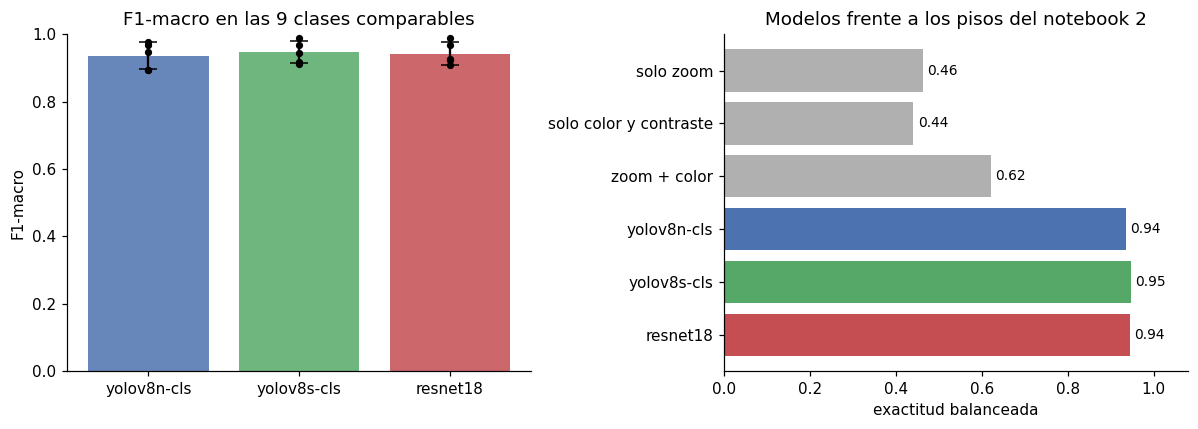

In [ ]:
pisos = pd.read_csv(OUT_DIR / "lineas_base.csv", sep=";", index_col=0)["exactitud_balanceada"]
exactitud = {v: balanced_accuracy_score(g["clase"], g["pred"]) for v, g in predicciones.groupby("modelo")}

fig, ejes = plt.subplots(1, 2, figsize=(11, 4))
for i, v in enumerate(VARIANTES):
    f1_v = por_pliegue.loc[por_pliegue["modelo"] == v, "F1-macro"]
    ejes[0].bar(i, f1_v.mean(), yerr=f1_v.std(), capsize=6, color=colores[v], alpha=0.85)
    ejes[0].scatter(np.full(len(f1_v), i), f1_v, color="black", s=14, zorder=3)
ejes[0].set_xticks(range(len(VARIANTES)), VARIANTES); ejes[0].set_ylim(0, 1)
ejes[0].set_ylabel("F1-macro"); ejes[0].set_title(f"F1-macro en las {len(COMPARABLES)} clases comparables")

etiquetas = list(pisos.index) + VARIANTES
valores = list(pisos.values) + [exactitud[v] for v in VARIANTES]
ejes[1].barh(etiquetas, valores, color=["#B0B0B0"] * len(pisos) + [colores[v] for v in VARIANTES])
for y_pos, val in enumerate(valores):
    ejes[1].text(val + 0.01, y_pos, f"{val:.2f}", va="center", fontsize=9)
ejes[1].set_xlim(0, 1.08); ejes[1].invert_yaxis()
ejes[1].set_xlabel("exactitud balanceada"); ejes[1].set_title("Modelos frente a los pisos del notebook 2")
fig.tight_layout()
plt.show()

Los tres modelos quedan entre 0,94 y 0,95 de exactitud balanceada, frente a 0,62 del mejor piso (zoom y color juntos). Aprenden algo que el zoom y el color no explican.

### YOLOv8n o YOLOv8s

La regla se fijó antes de entrenar, para no elegir después según convenga. En cada pliegue se calcula `d = F1-macro(s) − F1-macro(n)`. Se adopta YOLOv8s solo si la media de `d` supera 0,02 **y** `d` es positiva en al menos 4 de los 5 pliegues, es decir, si mejora al menos dos puntos y lo hace de forma consistente. Si no, se conserva YOLOv8n, que es más liviano.

In [ ]:
f1_n = por_pliegue[por_pliegue["modelo"] == "yolov8n-cls"].set_index("pliegue")["F1-macro"]
f1_s = por_pliegue[por_pliegue["modelo"] == "yolov8s-cls"].set_index("pliegue")["F1-macro"]
d = f1_s - f1_n
VARIANTE_ELEGIDA = "yolov8s-cls" if (d.mean() > 0.02 and (d > 0).sum() >= 4) else "yolov8n-cls"
display(pd.DataFrame({"F1-macro YOLOv8n": f1_n, "F1-macro YOLOv8s": f1_s, "d": d}).T.round(3))
print(f"Media de d: {d.mean():+.3f}; pliegues con d > 0: {(d > 0).sum()} de {N_PLIEGUES}. Modelo elegido: {VARIANTE_ELEGIDA}")

pliegue,1,2,3,4,5
F1-macro YOLOv8n,0.895,0.893,0.949,0.968,0.976
F1-macro YOLOv8s,0.918,0.912,0.944,0.968,0.989
d,0.024,0.019,-0.005,0.000,0.013


Media de d: +0.010; pliegues con d > 0: 3 de 5. Modelo elegido: yolov8n-cls


YOLOv8s mejora en los pliegues 1, 2 y 5, empata en el 4 y pierde en el 3. La media es +0,010, por debajo de +0,02, y solo 3 de los 5 pliegues son positivos. No se cumple ninguno de los dos criterios: se conserva YOLOv8n.

### ¿Qué justifica YOLOv8n frente a ResNet-18?

Con los promedios no alcanza: las diferencias entre modelos son menores que la variación entre pliegues. Hacen falta dos comparaciones más: si los modelos clasifican distinto de verdad y cuánto cuesta cada uno.

**¿Son distintos de verdad?** La **prueba de McNemar** compara dos modelos sobre las mismas 499 imágenes en 4 pasos:

1. **Se separan las imágenes en cuatro grupos:** las que aciertan ambos, las que fallan ambos, las que solo acierta el primero y las que solo acierta el segundo.
2. **Se descartan los empates.** Las imágenes que ambos aciertan o ambos fallan no dicen cuál es mejor; solo cuentan los desacuerdos.
3. **Se compara el reparto de los desacuerdos con el de una moneda.** Si los dos modelos fueran igual de buenos, cada desacuerdo lo ganaría uno u otro con probabilidad 1/2, como una moneda lanzada tantas veces como desacuerdos haya.
4. **Se calcula el valor p:** la probabilidad de que esa moneda dé un reparto al menos tan desigual como el observado. Si es menor que 0,05, el reparto es demasiado desigual para atribuirlo al azar y un modelo es mejor; si es mayor, la diferencia es compatible con el azar.

Se usa la versión exacta, que cuenta todos los resultados posibles de la moneda (distribución binomial), adecuada cuando los desacuerdos son pocos.

La prueba supone que cada imagen es independiente, y las de un mismo sitio no lo son del todo. Por eso el valor p sale algo más bajo de lo que debería; si aun así supera 0,05, la conclusión de que no hay diferencia se refuerza.

**¿Cuánto cuesta cada uno?** El **número de pesos** (el tamaño del modelo) y el **tiempo de inferencia** (lo que tarda en clasificar una imagen). El tiempo depende de la máquina y solo sirve para comparar modelos medidos en la misma.

In [ ]:
acierta = {v: g.set_index("id").sort_index().eval("clase == pred") for v, g in predicciones.groupby("modelo")}
filas = []
for a, b in [("yolov8n-cls", "yolov8s-cls"), ("yolov8n-cls", "resnet18"), ("yolov8s-cls", "resnet18")]:
    solo_a, solo_b = int((acierta[a] & ~acierta[b]).sum()), int((~acierta[a] & acierta[b]).sum())
    filas.append({"comparación": f"{a} frente a {b}", "solo acierta el primero": solo_a, "solo acierta el segundo": solo_b,
                  "valor p": binomtest(solo_a, solo_a + solo_b, 0.5).pvalue})
display(pd.DataFrame(filas).set_index("comparación").round(3))

@torch.no_grad()
def costo(variante, repeticiones=30):
    red, _, _ = construir_modelo(variante)
    red.eval()
    x = torch.rand(BATCH, 3, IMGSZ, IMGSZ, device=DISPOSITIVO)
    for _ in range(5):                      # calentamiento
        logits_de(red, x)
    if DISPOSITIVO == "cuda":
        torch.cuda.synchronize()
    inicio = time.perf_counter()
    for _ in range(repeticiones):
        logits_de(red, x)
    if DISPOSITIVO == "cuda":
        torch.cuda.synchronize()
    return {"millones de pesos": sum(p.numel() for p in red.parameters()) / 1e6,
            "ms por imagen": (time.perf_counter() - inicio) / (repeticiones * BATCH) * 1000,
            "F1-macro": media.loc[variante, "F1-macro"]}

display(pd.DataFrame({v: costo(v) for v in VARIANTES}).T.round(3))

,solo acierta el primero,solo acierta el segundo,valor p
comparación,,,
yolov8n-cls frente a yolov8s-cls,7,13,0.263
yolov8n-cls frente a resnet18,10,14,0.541
yolov8s-cls frente a resnet18,10,8,0.815


,millones de pesos,ms por imagen,F1-macro
yolov8n-cls,1.451,0.496,0.936
yolov8s-cls,5.094,0.687,0.946
resnet18,11.182,0.994,0.942


YOLOv8n y ResNet-18 discrepan en 24 imágenes: ResNet-18 acierta 14 que YOLOv8n falla, y YOLOv8n acierta 10 que ResNet-18 falla. Un reparto de 14 a 10 es compatible con el azar (valor p 0,54). Lo mismo pasa con YOLOv8n frente a YOLOv8s (13 a 7, valor p 0,26) y con YOLOv8s frente a ResNet-18 (10 a 8, valor p 0,82). No hay evidencia de que ninguno clasifique mejor que los otros.

Donde sí se separan es en el costo. YOLOv8n tiene 1,45 millones de pesos, 3,5 veces menos que YOLOv8s (5,1) y casi 8 veces menos que ResNet-18 (11,2), y en esta máquina clasifica una imagen en 0,496 milisegundos frente a 0,994 milisegundos de ResNet-18. La comparación no muestra que YOLO sea más preciso que una red clásica; muestra que el más pequeño de los tres rinde lo mismo que uno casi ocho veces más grande, y eso justifica elegirlo.

## 3.5 Dónde acierta y dónde se equivoca

Se juntan las predicciones de los cinco pliegues (cada imagen predicha por un modelo que no la vio) para mirar al modelo elegido clase por clase. La **matriz de confusión** cuenta, para cada clase real (filas), a qué clase la asignó el modelo (columnas): la diagonal son los aciertos y lo demás son errores, cuya posición dice con qué se confunde cada clase. El color es la proporción dentro de cada fila y el número, la cantidad de imágenes.

La clase que interesa es H2. Ginzburg et al. (2025) señalan sus confusiones con Impact crater y Salt lake; Jagüey se añade porque es la clase central de este proyecto.

,precisión,recall,F1,imágenes
Fairy circle,0.980,1.00,0.990,49
Fairy fort,0.960,0.96,0.960,50
Farm circle,0.980,1.00,0.990,50
Flooded dune,0.943,1.00,0.971,50
H2,0.857,0.84,0.848,50
Impact crater,0.955,0.84,0.894,50
Jaguey,0.980,0.96,0.970,50
Karst,0.920,0.92,0.920,50
Salt lake,0.917,0.88,0.898,50
Thermokarst,0.873,0.96,0.914,50


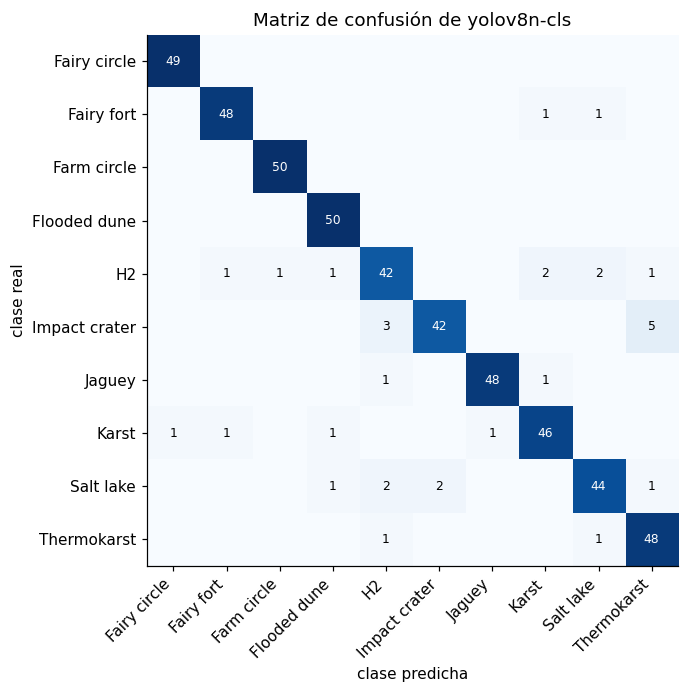

In [ ]:
oof = predicciones[predicciones["modelo"] == VARIANTE_ELEGIDA]
prec, rec, f1c, sop = precision_recall_fscore_support(oof["clase"], oof["pred"], labels=CLASES, zero_division=0)
display(pd.DataFrame({"precisión": prec, "recall": rec, "F1": f1c, "imágenes": sop}, index=CLASES).round(3))

cm = confusion_matrix(oof["clase"], oof["pred"], labels=CLASES)
cm_fila = cm / cm.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(8, 6.4))
ax.imshow(cm_fila, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(CLASES)), CLASES, rotation=45, ha="right"); ax.set_yticks(range(len(CLASES)), CLASES)
for (i, j), n in np.ndenumerate(cm):
    if n:
        ax.text(j, i, n, ha="center", va="center", fontsize=8, color="white" if cm_fila[i, j] > 0.5 else "black")
ax.set_xlabel("clase predicha"); ax.set_ylabel("clase real"); ax.set_title(f"Matriz de confusión de {VARIANTE_ELEGIDA}")
fig.tight_layout()
plt.show()

H2 acierta 42 de sus 50 imágenes (recall 0,84, precisión 0,86), y su F1 de 0,85 es el más bajo de las diez clases. Sus 8 errores se reparten entre seis clases, sin una confusión dominante: 2 con Karst, 2 con Salt lake y uno con Fairy fort, Farm circle, Flooded dune y Thermokarst.

Con Jagüey casi no hay confusiones: ninguna H2 se predice como Jagüey y solo un Jagüey se predice como H2. Confusiones de la literatura: Ninguna H2 se predice como Impact crater, pero 3 cráteres se predicen como H2. El error más repetido del modelo es otro: 5 Impact crater predichos como Thermokarst.

### La probabilidad de H2 como orden de prioridad

Para priorizar estructuras no basta con saber si el modelo elige H2; importa el número que le asigna, su probabilidad de H2, que aquí se abrevia **P(H2)**. Si se ordenan las imágenes de mayor a menor P(H2) y se fija un **umbral**, todo lo que queda por encima es candidato. Un umbral alto deja pocos candidatos, casi todos verdaderos (precisión alta, recall bajo); uno bajo encuentra casi todas las H2 pero deja colar otras clases.

La **curva de precisión y recall** (curva PR) dibuja ese intercambio para todos los umbrales: cada punto es un umbral, con su recall en el eje horizontal y su precisión en el vertical. El área bajo la curva es la PR-AUC. La línea punteada es lo que daría ordenar al azar: una precisión igual a la proporción de H2 (1 de cada 10). A la derecha, la P(H2) de cada imagen según su clase real; lo que interesa es qué clases reciben P(H2) altas sin ser H2, porque serían las que se colarían en una lista de prioridad.

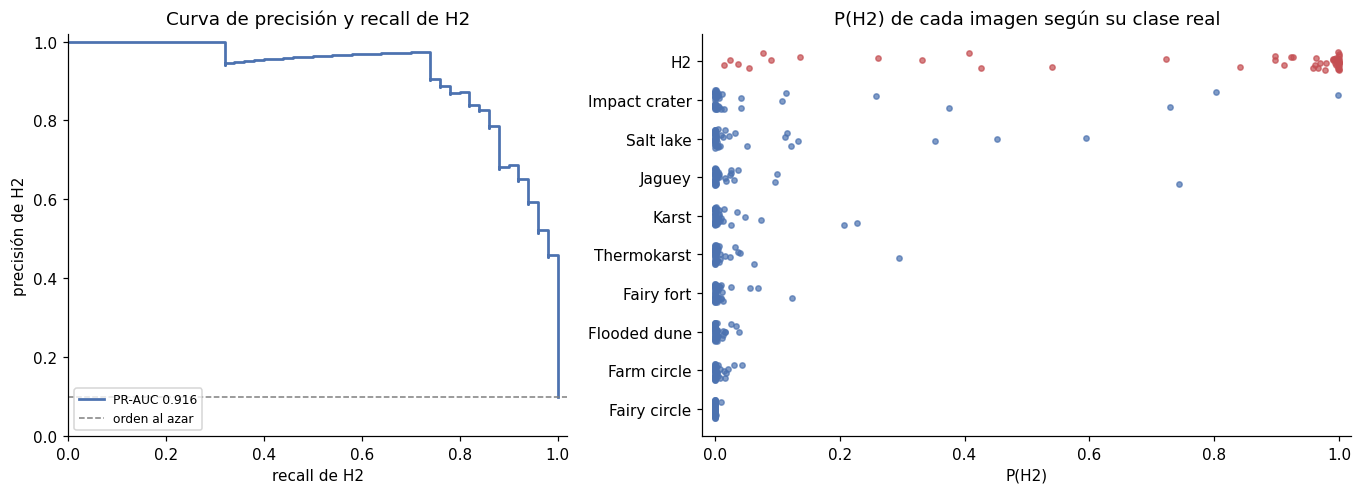

,"P(H2) > 0,1","P(H2) > 0,5"
clase,,
Fairy fort,1,0
Impact crater,7,3
Jaguey,1,1
Karst,2,0
Salt lake,7,1
Thermokarst,1,0


In [ ]:
es_h2 = (oof["clase"] == "H2").to_numpy()
prec_c, rec_c, _ = precision_recall_curve(es_h2, oof["prob_H2"])

fig, ejes = plt.subplots(1, 2, figsize=(12.5, 4.6), gridspec_kw={"width_ratios": [1, 1.3]})
ejes[0].step(rec_c, prec_c, where="post", color=colores[VARIANTE_ELEGIDA], lw=1.8, label=f"PR-AUC {average_precision_score(es_h2, oof['prob_H2']):.3f}")
ejes[0].axhline(es_h2.mean(), color="gray", ls="--", lw=1, label="orden al azar")
ejes[0].set_xlim(0, 1.02); ejes[0].set_ylim(0, 1.02); ejes[0].legend(fontsize=8, loc="lower left")
ejes[0].set_xlabel("recall de H2"); ejes[0].set_ylabel("precisión de H2"); ejes[0].set_title("Curva de precisión y recall de H2")

orden = oof.groupby("clase")["prob_H2"].mean().sort_values().index
rng = np.random.default_rng(SEMILLA)
for fila, clase in enumerate(orden):
    v = oof.loc[oof["clase"] == clase, "prob_H2"]
    ejes[1].scatter(v, fila + rng.uniform(-0.25, 0.25, len(v)), s=12, alpha=0.7, color="#C44E52" if clase == "H2" else "#4C72B0")
ejes[1].set_yticks(range(len(orden)), orden); ejes[1].set_xlim(-0.02, 1.02)
ejes[1].set_xlabel("P(H2)"); ejes[1].set_title("P(H2) de cada imagen según su clase real")
fig.tight_layout()
plt.show()

otras = oof[oof["clase"] != "H2"]
display(pd.DataFrame({"P(H2) > 0,1": otras[otras["prob_H2"] > 0.1]["clase"].value_counts(),
                      "P(H2) > 0,5": otras[otras["prob_H2"] > 0.5]["clase"].value_counts()}).fillna(0).astype(int))

La curva se mantiene en precisión 1 hasta un recall de 0,32 y por encima de 0,94 hasta 0,74: al ordenar por P(H2), las primeras tres cuartas partes de las H2 aparecen casi sin intrusas. Después cae por escalones hasta 0,46 con recall 1, porque las últimas H2 tienen una P(H2) tan baja que alcanzarlas obliga a aceptar muchas imágenes de otras clases.

A la derecha se ve por qué. La mayoría de las H2 tienen P(H2) por encima de 0,9, pero alrededor de una docena quedan repartidas entre 0 y 0,6, mezcladas con las demás. Las intrusas vienen sobre todo de Impact crater y Salt lake (7 imágenes de cada una por encima de 0,1, y 3 cráteres por encima de 0,5), dos de las confusiones de la literatura. Jagüey casi no interviene: solo 1 de sus 50 imágenes supera 0,1.

### Qué H2 reconoce: desglose por región

Las 50 H2 de validación cruzada vienen de unas pocas regiones del mundo, separadas por miles de kilómetros y cada una con su paisaje y, como mostró el notebook 2, su propio rango de zoom. Un recall de 0,84 puede ser el promedio de regiones que el modelo reconoce siempre y otras que casi nunca reconoce, y eso cambia lo que se puede esperar en La Guajira.

Las H2 se agrupan por región: dos imágenes quedan juntas si las une una cadena de saltos de menos de 1.000 km. Cada región se nombra por su latitud y longitud aproximadas.

In [ ]:
h2 = oof[oof["clase"] == "H2"].merge(cv[["id", "lat", "lon"]], on="id")
h2["región"] = regiones(h2["lat"], h2["lon"])
filas = []
for region, g in h2.groupby("región", sort=False):
    errores = g.loc[g["pred"] != "H2", "pred"].value_counts()
    filas.append({"región": region, "imágenes": len(g), "zooms": ", ".join(map(str, sorted(g["zoom"].unique()))),
                  "recall": (g["pred"] == "H2").mean(), "P(H2) mediana": g["prob_H2"].median(),
                  "errores (predichas como)": ", ".join(f"{c} ({n})" for c, n in errores.items()) or "—"})
display(pd.DataFrame(filas).set_index("región").round(3))

,imágenes,zooms,recall,P(H2) mediana,errores (predichas como)
región,,,,,
21°S 18°E,15,"18, 19",1.000,0.993,—
16°S 45°O,22,"17, 18",1.000,0.998,—
51°N 42°E,10,"15, 16, 17, 18",0.300,0.112,"Salt lake (2), Karst (2), Thermokarst (1), Fai..."
34°N 79°O,3,"15, 17, 18",0.667,0.331,Farm circle (1)


El recall de 0,84 es el promedio de dos situaciones muy distintas. Las H2 de 21°S 18°E (Namibia y el norte de Sudáfrica, 15 imágenes) y de 16°S 45°O (centro de Brasil, 22) se reconocen todas, con P(H2) mediana de 0,993 y 0,998. De las de 51°N 42°E (sur de Rusia, 10) se reconocen solo 3, con P(H2) mediana de 0,112, y de las de 34°N 79°O (las Carolinas, en Estados Unidos, 3), se reconocen 2. Los ocho errores de H2 salen de estas dos regiones: siete de Rusia y uno de las Carolinas.

Las regiones bien reconocidas son las que más imágenes aportan, se capturaron con zooms altos (17 a 19) y tienen paisajes de sabana con vegetación dispersa. Las mal reconocidas incluyen los zooms más bajos (15 y 16), es decir, estructuras más grandes vistas desde más lejos, en otro tipo de paisaje. A eso se suma el reparto por pliegues: 9 de las 10 H2 rusas quedaron en el mismo pliegue, así que al evaluarlas el modelo había entrenado con una sola H2 rusa y las vio casi como una región nueva.  El modelo reconoce con seguridad las H2 que se parecen a las de las regiones con más ejemplos, y no las demás. Queda abierto a cuál de estos tipos se parecerán las posibles candidatas a SCD de La Guajira; el notebook 4 (sección 4.9) lo pone a prueba entrenando sin una región y viendo qué pasa con sus H2.

## 3.6 Clases evaluadas aparte

Las clases sin imágenes de validación en alguno de los cinco pliegues no entran al promedio. Su desempeño se calcula juntando todas las predicciones que sí existen para ellas. La tabla indica también de cuántos sitios reales vienen esas imágenes y en cuántos pliegues aparecen: cuantos menos, menos fiable es la cifra.

In [ ]:
filas = []
for clase in APARTE:
    sitios, pliegues = cv.loc[cv["clase"] == clase, "grupo_particion"].nunique(), cv.loc[cv["clase"] == clase, "fold_val"].nunique()
    for v, g in predicciones.groupby("modelo", sort=False):
        _, r_, f_, s_ = precision_recall_fscore_support(g["clase"], g["pred"], labels=[clase], zero_division=0)
        filas.append({"clase": clase, "modelo": v, "F1": f_[0], "recall": r_[0], "imágenes": int(s_[0]),
                      "sitios reales": sitios, "pliegues con esta clase": pliegues})
display(pd.DataFrame(filas).set_index(["clase", "modelo"]).round(3))

F1  recall  imágenes  sitios reales  pliegues con esta clase
clase        modelo                                                                     
Fairy circle yolov8n-cls  0.99     1.0        49              2                        2
             yolov8s-cls  0.99     1.0        49              2                        2
             resnet18     1.00     1.0        49              2                        2

Fairy circle sale casi perfecta con los tres modelos (F1 entre 0,99 y 1,00 sobre 49 imágenes), pero esas imágenes vienen de solo dos sitios y aparecen en dos de los cinco pliegues. No prueba que el modelo distinga su forma: puede estar reconociendo el sitio o el zoom, que en esta clase es siempre 21 y con el que el notebook 2 ya la reconocía al 100 %. Por eso no se promedia con el resto.

## 3.7 Resultados guardados

Se guardan en `salidas/` las predicciones de validación de los tres modelos (`oof_predicciones.csv`, con la probabilidad de cada clase para cada imagen), la historia del entrenamiento y un resumen con el modelo elegido y la mediana de la mejor época de cada etapa, que el notebook 4 usa para entrenar el modelo final. Los 15 modelos ya quedaron en `salidas/modelos/`.

In [ ]:
mediana_mejor_epoca = {v: {f"etapa_{e}": float(np.median([resumenes[(v, k)][f"mejor_epoca_etapa_{e}"] for k in range(1, N_PLIEGUES + 1)]))
                           for e in (1, 2)} for v in VARIANTES}
predicciones.to_csv(OUT_DIR / "oof_predicciones.csv", sep=";", index=False, encoding="utf-8-sig")
historia.to_csv(OUT_DIR / "historia_entrenamiento.csv", sep=";", index=False, encoding="utf-8-sig")
resumen = {"particion_hash": hash_particion(part), "variante_elegida": VARIANTE_ELEGIDA, "clases": CLASES,
           "clases_comparables": COMPARABLES, "clases_aparte": APARTE, "mediana_mejor_epoca": mediana_mejor_epoca,
           "protocolo": {"imgsz": IMGSZ, "batch": BATCH, "paciencia": PACIENCIA, "etapa_1": ETAPA_1, "etapa_2": ETAPA_2, "semilla": SEMILLA},
           "f1_macro": {v: {"media": float(media.loc[v, "F1-macro"]), "desviacion": float(desv.loc[v, "F1-macro"])} for v in VARIANTES}}
(OUT_DIR / "resumen_modelamiento.json").write_text(json.dumps(resumen, ensure_ascii=False, indent=1), encoding="utf-8")
print("Mediana de la mejor época del modelo elegido:", mediana_mejor_epoca[VARIANTE_ELEGIDA])

Mediana de la mejor época del modelo elegido: {'etapa_1': 16.0, 'etapa_2': 7.0}


## Resumen

- Se entrenaron 3 modelos en 5 pliegues cada uno, con el mismo protocolo y sin usar el holdout.
- F1-macro en las 9 clases comparables: YOLOv8n 0,936 ± 0,040, YOLOv8s 0,946 ± 0,033 y ResNet-18 0,942 ± 0,034. Las diferencias son menores que la variación entre pliegues, y la prueba de McNemar no encuentra diferencias entre ningún par (valores p de 0,26 a 0,82).
- Los tres superan con claridad los pisos del notebook 2 (0,94 a 0,95 de exactitud balanceada frente a 0,62).
- Se conserva YOLOv8n: YOLOv8s no cumple la regla fijada de antemano, y YOLOv8n rinde lo mismo que ResNet-18 con casi 8 veces menos pesos.
- H2 tiene recall 0,84 y precisión 0,86, el F1 más bajo de las diez clases. Ordenando por P(H2), las tres primeras cuartas partes de las H2 salen casi sin intrusas; las que se cuelan son sobre todo cráteres y lagos salinos.
- Ese recall esconde dos grupos: las H2 de Namibia y Brasil se reconocen todas, y las de Rusia casi nunca (3 de 10) y las de las Carolinas a medias (2 de 3); 9 de las 10 rusas se evaluaron casi sin ejemplos rusos en el entrenamiento. Todos los errores de H2 vienen de esas dos regiones.
- Fairy circle se evaluó aparte por tener imágenes de validación en solo 2 pliegues.
- Las cifras de validación cruzada son algo optimistas; la estimación sin sesgo es la del holdout, en el notebook 4.